## Part A

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

DATA_DIR = Path('data/att_faces')
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_SHAPE = (112, 92)
SEED = 42
assert DATA_DIR.is_dir(), f'Dataset folder not found: {DATA_DIR.resolve()}'

Shape: (112, 92) dtype: uint8
Min: 11 Max: 234 Mean: 128.33821816770185 Std: 53.31363778766429
Top-left 8x8 pixels:
 [[48 49 45 47 49 57 39 42]
 [45 52 39 46 56 45 39 47]
 [45 50 42 51 51 45 40 48]
 [49 46 47 47 50 47 42 45]
 [46 46 47 48 48 44 43 44]
 [47 45 48 51 44 35 41 49]
 [45 48 46 50 33 37 42 51]
 [47 49 47 55 40 31 54 52]]


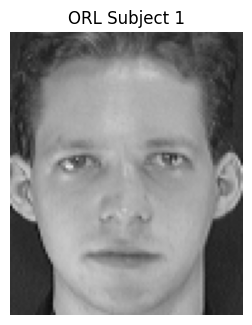

In [2]:
image_path = DATA_DIR / 's1' / '1.pgm'
img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
assert img is not None and img.shape == IMAGE_SHAPE, f'Unable to read {image_path}'
print('Shape:', img.shape, 'dtype:', img.dtype)
print('Min:', img.min(), 'Max:', img.max(), 'Mean:', img.mean(), 'Std:', img.std())
print('Top-left 8x8 pixels:\n', img[:8, :8])
plt.figure(figsize=(3, 4)); plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('ORL Subject 1'); plt.axis('off'); plt.show()

Image: (112, 92) Flattened: (10304,)


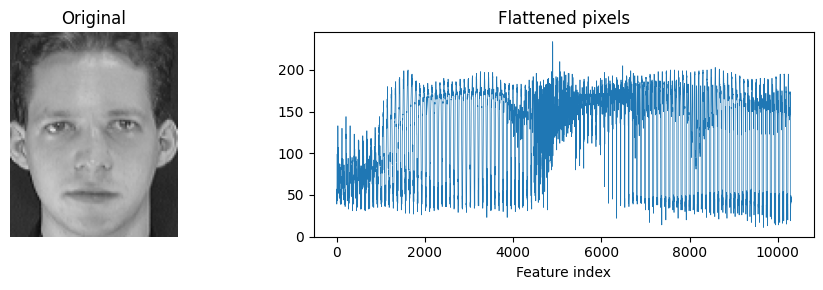

In [3]:
flat = img.astype(np.float32).reshape(-1)
restored = flat.reshape(IMAGE_SHAPE)
print('Image:', img.shape, 'Flattened:', flat.shape)
assert np.array_equal(img, restored)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].imshow(img, cmap='gray', vmin=0, vmax=255); ax[0].axis('off'); ax[0].set_title('Original')
ax[1].plot(flat, lw=.5); ax[1].set_title('Flattened pixels'); ax[1].set_xlabel('Feature index')
plt.tight_layout(); plt.show()

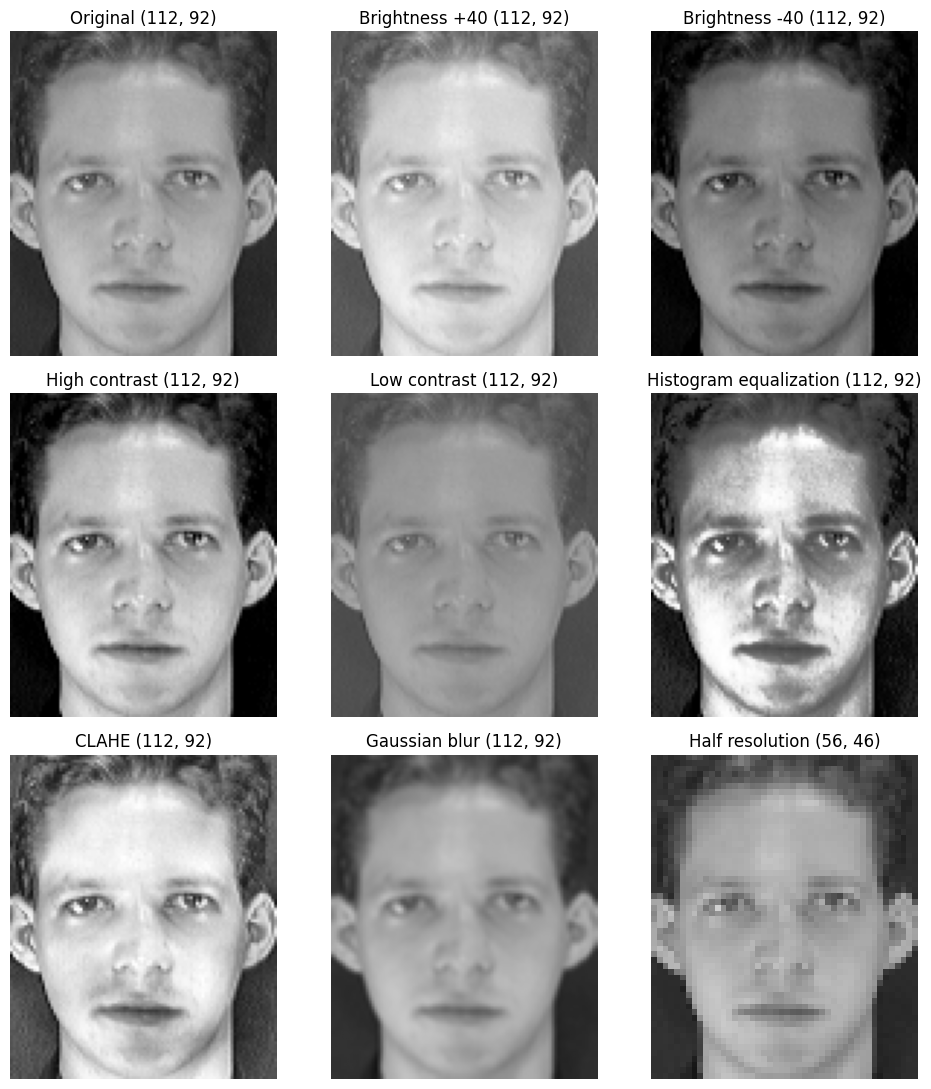

In [5]:
def adjust_brightness(image, beta):
    return np.clip(image.astype(np.float32) + beta, 0, 255).astype(np.uint8)

def adjust_contrast(image, factor):
    return np.clip(factor * (image.astype(np.float32) - 127.5) + 127.5, 0, 255).astype(np.uint8)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
gallery = {
    'Original': img,
    'Brightness +40': adjust_brightness(img, 40),
    'Brightness -40': adjust_brightness(img, -40),
    'High contrast': adjust_contrast(img, 1.5),
    'Low contrast': adjust_contrast(img, .6),
    'Histogram equalization': cv2.equalizeHist(img),
    'CLAHE': clahe.apply(img),
    'Gaussian blur': cv2.GaussianBlur(img, (3, 3), 0),
    'Half resolution': cv2.resize(img, (46, 56), interpolation=cv2.INTER_AREA),
}
fig, axes = plt.subplots(3, 3, figsize=(10, 11))
for ax, (name, image) in zip(axes.flat, gallery.items()):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'{name} {image.shape}'); ax.axis('off')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'single_image_preprocessing.png', dpi=180); plt.show()


In [6]:
subject_dirs = sorted(DATA_DIR.glob('s[0-9]*'), key=lambda p: int(p.name[1:]))
X_list, y_list, image_paths = [], [], []
for folder in subject_dirs:
    subject = int(folder.name[1:])
    paths = sorted(folder.glob('*.pgm'), key=lambda p: int(p.stem))
    for path in paths:
        image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if image is None or image.shape != IMAGE_SHAPE:
            raise ValueError(f'Invalid image or shape: {path}')
        X_list.append(image.astype(np.float32).reshape(-1))
        y_list.append(subject)
        image_paths.append(str(path))
X = np.stack(X_list); y = np.asarray(y_list, dtype=np.int32)
classes, counts = np.unique(y, return_counts=True)
assert X.shape == (400, 10304) and len(classes) == 40 and np.all(counts == 10)
assert np.isfinite(X).all()
print('X:', X.shape, 'y:', y.shape, 'subjects:', len(classes))

X: (400, 10304) y: (400,) subjects: 40


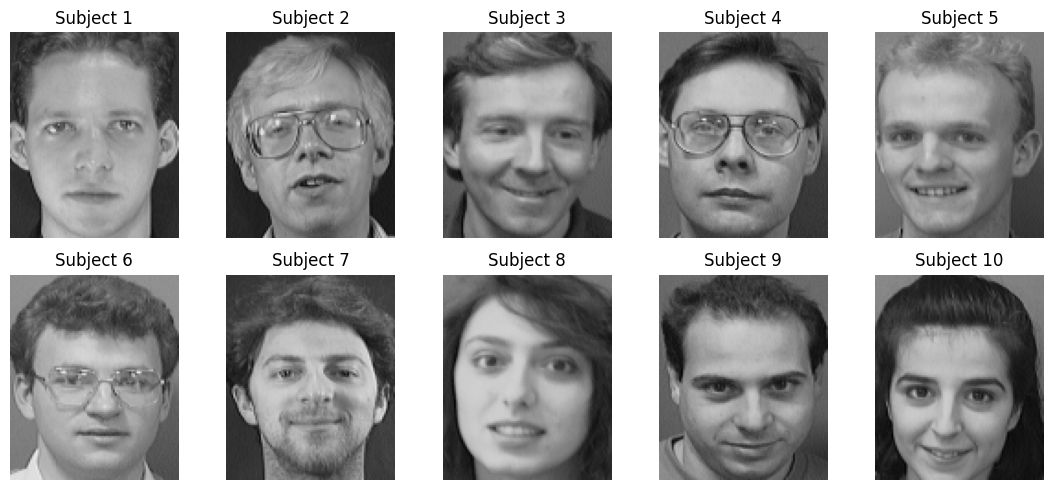

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax, subject in zip(axes.flat, classes[:10]):
    idx = np.where(y == subject)[0][0]
    ax.imshow(X[idx].reshape(IMAGE_SHAPE), cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Subject {subject}'); ax.axis('off')
plt.tight_layout(); plt.show()

In [9]:
rng = np.random.default_rng(SEED)
train_indices, test_indices = [], []
for subject in classes:
    shuffled = rng.permutation(np.where(y == subject)[0])
    train_indices.extend(shuffled[:8]); test_indices.extend(shuffled[8:])
train_indices = np.asarray(train_indices)
test_indices = np.asarray(test_indices)
X_train, y_train = X[train_indices], y[train_indices]
X_test, y_test = X[test_indices], y[test_indices]
assert not np.intersect1d(train_indices, test_indices).size
assert X_train.shape == (320, 10304) and X_test.shape == (80, 10304)
assert np.all(np.unique(y_train, return_counts=True)[1] == 8)
assert np.all(np.unique(y_test, return_counts=True)[1] == 2)
np.savez(RESULTS_DIR / 'split_indices.npz', train_indices=train_indices, test_indices=test_indices)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (320, 10304) Test: (80, 10304)


## Part B 

Mean: (10304,) Centered: (320, 10304)


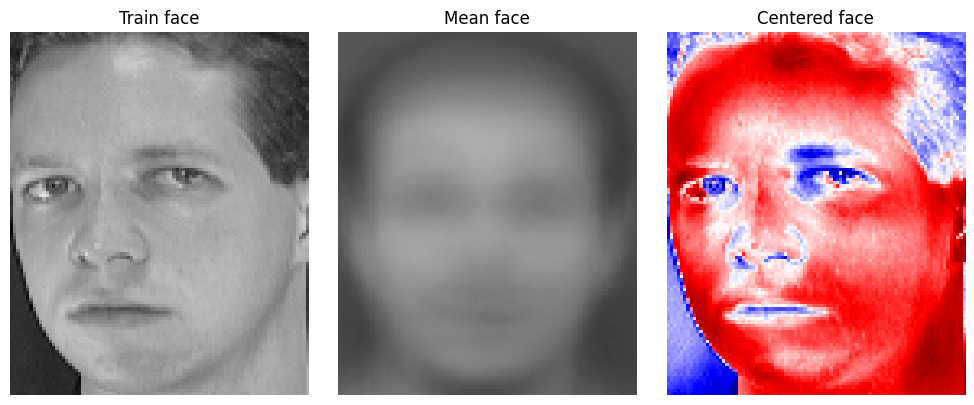

In [10]:
X_train_pca = X_train.astype(np.float64)
mean_face = X_train_pca.mean(axis=0)
A = X_train_pca - mean_face
assert np.allclose(A.mean(axis=0), 0, atol=1e-10)
print('Mean:', mean_face.shape, 'Centered:', A.shape)
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
for ax, arr, title in zip(axes, [X_train_pca[0], mean_face, A[0]], ['Train face', 'Mean face', 'Centered face']):
    arr = arr.reshape(IMAGE_SHAPE)
    lim = max(abs(arr.min()), abs(arr.max())) if title == 'Centered face' else None
    ax.imshow(arr, cmap='seismic' if lim else 'gray', vmin=-lim if lim else 0, vmax=lim if lim else 255)
    ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'mean_centering.png', dpi=180); plt.show()

In [11]:
U, S, Vt = np.linalg.svd(A, full_matrices=False)
n_samples = A.shape[0]
eigenvalues = S**2 / (n_samples - 1)
explained_variance_ratio = eigenvalues / eigenvalues.sum()
cumulative_variance = np.cumsum(explained_variance_ratio)
k_90 = int(np.searchsorted(cumulative_variance, .90) + 1)
print('U:', U.shape, 'S:', S.shape, 'Vt:', Vt.shape)
print('k for 90% variance:', k_90, 'Retained:', f'{cumulative_variance[k_90-1]:.4%}')

U: (320, 320) S: (320,) Vt: (320, 10304)
k for 90% variance: 99 Retained: 90.0121%


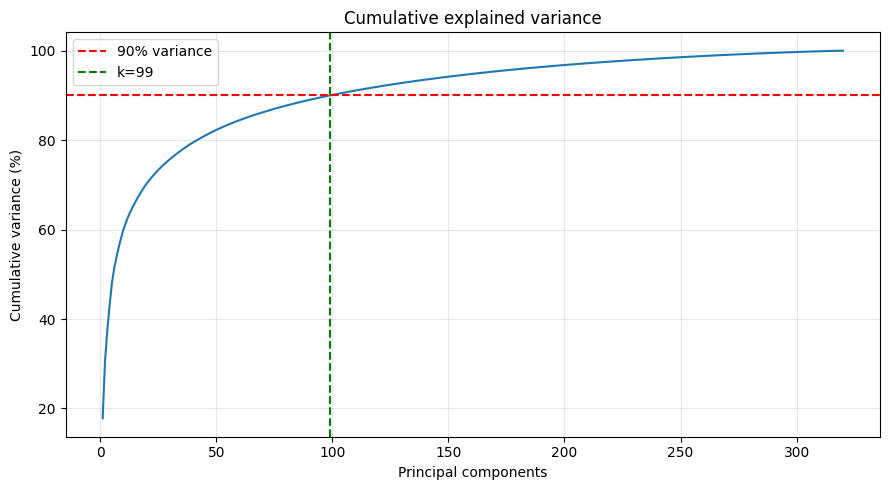

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(S)+1), 100*cumulative_variance)
plt.axhline(90, c='red', ls='--', label='90% variance')
plt.axvline(k_90, c='green', ls='--', label=f'k={k_90}')
plt.xlabel('Principal components'); plt.ylabel('Cumulative variance (%)')
plt.title('Cumulative explained variance'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'explained_variance.png', dpi=220); plt.show()

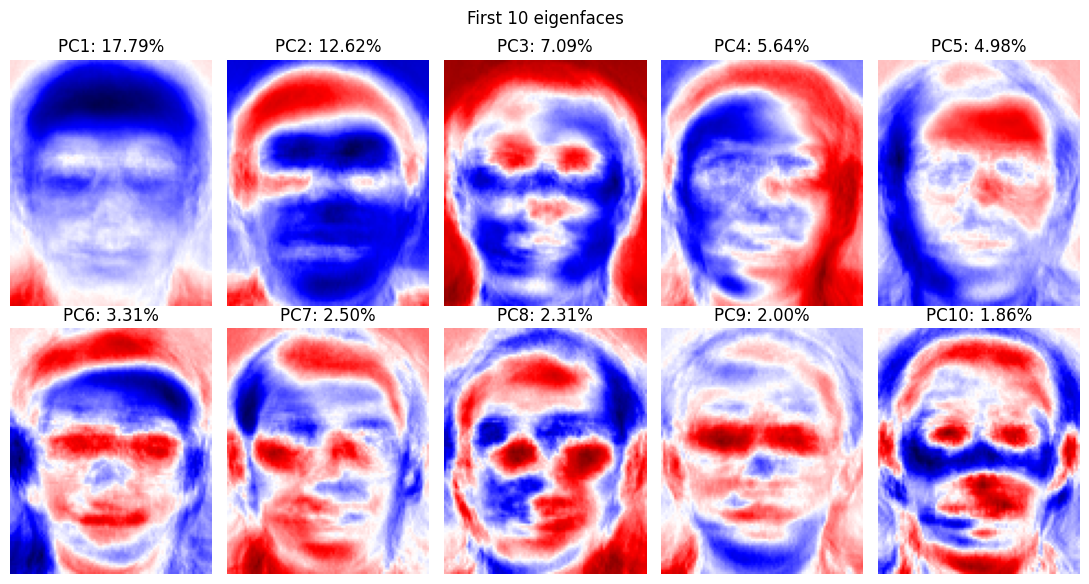

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(11, 6))
for i, ax in enumerate(axes.flat):
    ef = Vt[i].reshape(IMAGE_SHAPE); bound = np.max(np.abs(ef))
    ax.imshow(ef, cmap='seismic', vmin=-bound, vmax=bound)
    ax.set_title(f'PC{i+1}: {100*explained_variance_ratio[i]:.2f}%'); ax.axis('off')
plt.suptitle('First 10 eigenfaces'); plt.tight_layout()
plt.savefig(RESULTS_DIR / 'eigenfaces.png', dpi=220); plt.show()

In [14]:
# Cross-check SVD directions with eigendecomposition of the SMALL sample-space matrix.
G = (A @ A.T) / (n_samples - 1)
eigvals, eigvecs = np.linalg.eigh(G)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
V_eig = (A.T @ eigvecs[:, :k_90]) / np.sqrt((n_samples-1)*eigvals[:k_90])
W = Vt[:k_90].T
alignment = np.linalg.svd(W.T @ V_eig, compute_uv=False)
assert np.allclose(eigenvalues[:k_90], eigvals[:k_90], rtol=1e-6)
assert np.allclose(W.T @ W, np.eye(k_90), atol=1e-8)
print('Eigenvalues agree:', True, 'Minimum subspace overlap:', alignment.min())

Eigenvalues agree: True Minimum subspace overlap: 0.9999999999999974


In [15]:
Z_train = A @ W
Z_test = (X_test.astype(np.float64) - mean_face) @ W
X_train_reconstructed = Z_train @ W.T + mean_face
X_test_reconstructed = Z_test @ W.T + mean_face
train_mse = np.mean((X_train.astype(np.float64) - X_train_reconstructed)**2)
test_mse = np.mean((X_test.astype(np.float64) - X_test_reconstructed)**2)
retained = 1 - np.sum((X_train - X_train_reconstructed)**2) / np.sum(A**2)
print('PCA train:', Z_train.shape, 'test:', Z_test.shape)
print('Reconstruction MSE train:', train_mse, 'test:', test_mse)
print('Training variance retained (reconstruction):', f'{retained:.4%}')

PCA train: (320, 99) test: (80, 99)
Reconstruction MSE train: 154.1293123808905 test: 323.20657932094036
Training variance retained (reconstruction): 90.0121%


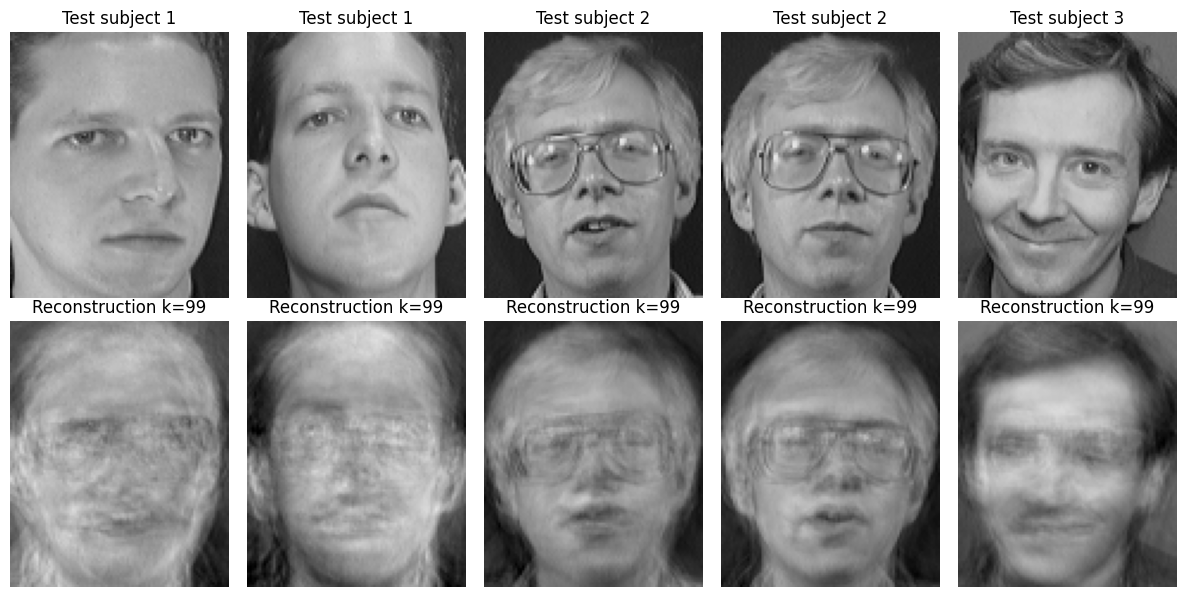

In [16]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i in range(5):
    axes[0, i].imshow(X_test[i].reshape(IMAGE_SHAPE), cmap='gray', vmin=0, vmax=255)
    axes[1, i].imshow(X_test_reconstructed[i].reshape(IMAGE_SHAPE), cmap='gray', vmin=0, vmax=255)
    axes[0, i].set_title(f'Test subject {y_test[i]}')
    axes[1, i].set_title(f'Reconstruction k={k_90}')
    axes[0, i].axis('off'); axes[1, i].axis('off')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'reconstruction_examples.png', dpi=220); plt.show()

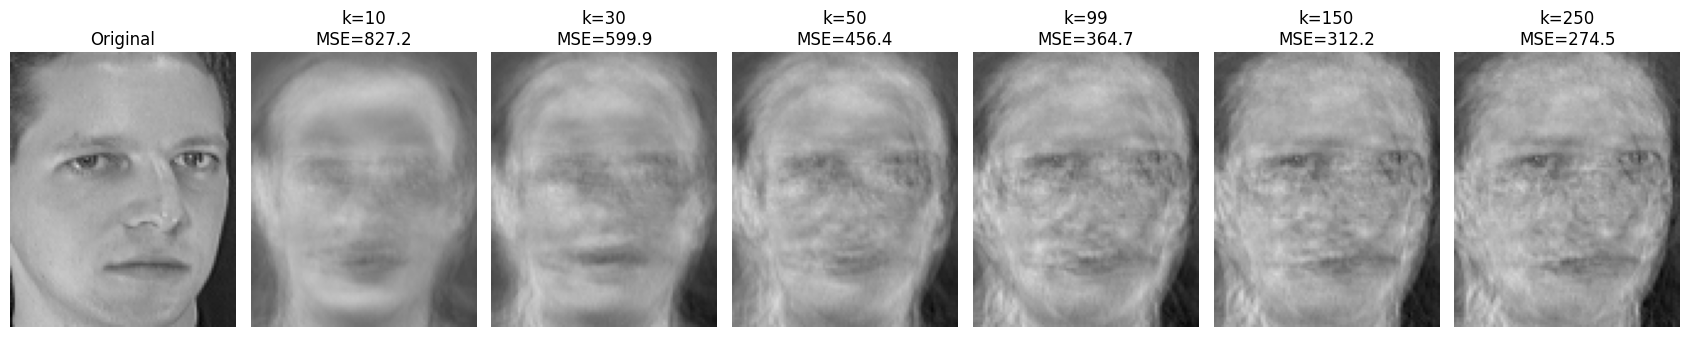

In [17]:
k_values_reconstruction = [10, 30, 50, k_90, 150, 250]
sample = X_test[0].astype(np.float64)
fig, axes = plt.subplots(1, len(k_values_reconstruction)+1, figsize=(17, 3.4))
axes[0].imshow(sample.reshape(IMAGE_SHAPE), cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original'); axes[0].axis('off')
for ax, k in zip(axes[1:], k_values_reconstruction):
    basis = Vt[:k].T
    recon = ((sample - mean_face) @ basis) @ basis.T + mean_face
    mse = np.mean((sample - recon)**2)
    ax.imshow(recon.reshape(IMAGE_SHAPE), cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'k={k}\nMSE={mse:.1f}'); ax.axis('off')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'reconstruction_by_k.png', dpi=220); plt.show()

In [18]:
n_images, n_features = X_train.shape
original_bytes = X_train.astype(np.uint8).nbytes
coeff_bytes = n_images*k_90*4
basis_bytes = n_features*k_90*4
mean_bytes = n_features*4
pca_bytes = coeff_bytes + basis_bytes + mean_bytes
storage_table = pd.DataFrame([
    {'Item':'Original uint8 images', 'KB':original_bytes/1024},
    {'Item':'PCA coefficients float32', 'KB':coeff_bytes/1024},
    {'Item':'PCA basis float32', 'KB':basis_bytes/1024},
    {'Item':'Mean face float32', 'KB':mean_bytes/1024},
    {'Item':'Total PCA', 'KB':pca_bytes/1024},
]); display(storage_table)
print('Per-face dimensionality reduction:', f'{100*(1-k_90/n_features):.2f}%')
print('Storage ratio:', f'{pca_bytes/original_bytes:.3f}')
storage_table.to_csv(RESULTS_DIR / 'storage_comparison.csv', index=False)

,Item,KB
0,Original uint8 images,3220.00
1,PCA coefficients float32,123.75
2,PCA basis float32,3984.75
3,Mean face float32,40.25
4,Total PCA,4148.75


Per-face dimensionality reduction: 99.04%
Storage ratio: 1.288


In [19]:
rng = np.random.default_rng(SEED)
inner_train_idx, val_idx = [], []
for subject in np.unique(y_train):
    ids = rng.permutation(np.where(y_train == subject)[0])
    inner_train_idx.extend(ids[:6]); val_idx.extend(ids[6:])
inner_train_idx = np.asarray(inner_train_idx); val_idx = np.asarray(val_idx)
X_inner_train = X_train[inner_train_idx].astype(np.float64)
X_val = X_train[val_idx].astype(np.float64)
y_inner_train, y_val = y_train[inner_train_idx], y_train[val_idx]
assert X_inner_train.shape == (240, 10304) and X_val.shape == (80, 10304)
assert not np.intersect1d(inner_train_idx, val_idx).size
print('Inner train:', X_inner_train.shape, 'Validation:', X_val.shape)

Inner train: (240, 10304) Validation: (80, 10304)


In [20]:
mean_inner = X_inner_train.mean(axis=0)
A_inner = X_inner_train - mean_inner
U_inner, S_inner, Vt_inner = np.linalg.svd(A_inner, full_matrices=False)
eigenvalues_inner = S_inner**2 / (len(X_inner_train)-1)
cumulative_inner = np.cumsum(eigenvalues_inner / eigenvalues_inner.sum())
k_inner = int(np.searchsorted(cumulative_inner, .90) + 1)
W_inner = Vt_inner[:k_inner].T
Z_inner_train = A_inner @ W_inner
Z_val = (X_val - mean_inner) @ W_inner
print('Validation PCA k:', k_inner, 'variance:', f'{cumulative_inner[k_inner-1]:.2%}')

Validation PCA k: 84 variance: 90.02%


## Part C 

In [21]:
def weighted_euclidean_distance(query, references, variances, alpha=0.0):
    """Distance from one (k,) query to (n,k) reference vectors."""
    variances = np.asarray(variances, dtype=np.float64)
    eps = 1e-6 * variances.max()
    weights = 1.0 / np.power(variances + eps, alpha)
    delta = references - query
    return np.sqrt(np.sum(weights * delta**2, axis=1))

def nearest_neighbor_predict(X_reference, y_reference, X_query, variances=None, alpha=0.0):
    predictions, indices = [], []
    for query in X_query:
        if variances is None:
            dist2 = np.sum((X_reference - query)**2, axis=1)
        else:
            dist2 = weighted_euclidean_distance(query, X_reference, variances, alpha)
        index = int(np.argmin(dist2))
        indices.append(index); predictions.append(y_reference[index])
    return np.asarray(predictions), np.asarray(indices)

In [22]:
alpha_values = [0.0, 0.25, 0.5, 0.75, 1.0]
alpha_rows = []
for alpha in alpha_values:
    p, _ = nearest_neighbor_predict(Z_inner_train, y_inner_train, Z_val,
                                    variances=eigenvalues_inner[:k_inner], alpha=alpha)
    alpha_rows.append({'alpha':alpha, 'Validation accuracy (%)':100*np.mean(p==y_val)})
alpha_table = pd.DataFrame(alpha_rows)
display(alpha_table)
# Primary rule: choose alpha with highest validation accuracy. Ties: choose lowest alpha.
best_alpha = float(alpha_table.loc[alpha_table['Validation accuracy (%)'].idxmax(), 'alpha'])
# Preserve mild weighting as a predeclared *comparison*, not a claim of best alpha.
weighted_alpha = 0.25
print('Selected performance-optimal alpha:', best_alpha)
print('Mild weighting used for the assignment comparison:', weighted_alpha)
alpha_table.to_csv(RESULTS_DIR / 'alpha_validation.csv', index=False)

,alpha,Validation accuracy (%)
0,0.00,97.50
1,0.25,97.50
2,0.50,93.75
3,0.75,92.50
4,1.00,88.75


Selected performance-optimal alpha: 0.0
Mild weighting used for the assignment comparison: 0.25


**Interpretation of the alpha tie.** If α=0 and α=0.25 tie, α=0 is selected by the explicit smallest-alpha tie-break rule. α=0.25 is reported separately as a mild weighted alternative, not claimed to be superior. Smaller raw numerical distances between different α values do not imply better recognition.

## Part D

In [23]:
knn_rows = []
for neighbor_k in [1,3,5,7]:
    clf = KNeighborsClassifier(n_neighbors=neighbor_k)
    clf.fit(Z_inner_train, y_inner_train)
    knn_rows.append({'Neighbors':neighbor_k, 'Accuracy (%)':100*np.mean(clf.predict(Z_val)==y_val)})
knn_table = pd.DataFrame(knn_rows); display(knn_table)
best_neighbors = int(knn_table.loc[knn_table['Accuracy (%)'].idxmax(), 'Neighbors'])

,Neighbors,Accuracy (%)
0,1,97.50
1,3,85.00
2,5,83.75
3,7,72.50


In [24]:
linear_rows = []
for C in [.01, .1, 1, 10, 100]:
    clf = SVC(kernel='linear', C=C)
    clf.fit(Z_inner_train, y_inner_train)
    linear_rows.append({'C':C, 'Accuracy (%)':100*np.mean(clf.predict(Z_val)==y_val)})
linear_table = pd.DataFrame(linear_rows); display(linear_table)

,C,Accuracy (%)
0,0.01,98.75
1,0.10,98.75
2,1.00,98.75
3,10.00,98.75
4,100.00,98.75


In [25]:
rbf_rows = []
for C in [.1, 1, 10, 100]:
    for gamma in ['scale', 1e-7, 1e-6, 1e-5]:
        clf = SVC(kernel='rbf', C=C, gamma=gamma)
        clf.fit(Z_inner_train, y_inner_train)
        rbf_rows.append({'C':C, 'gamma':gamma, 'Accuracy (%)':100*np.mean(clf.predict(Z_val)==y_val)})
rbf_table = pd.DataFrame(rbf_rows); display(rbf_table.sort_values('Accuracy (%)', ascending=False).head(8))

,C,gamma,Accuracy (%)
12,100.0,scale,98.75
13,100.0,0.0,98.75
9,10.0,0.0,98.75
8,10.0,scale,98.75
5,1.0,0.0,96.25
4,1.0,scale,95.00
0,0.1,scale,92.50
1,0.1,0.0,92.50


In [26]:
logistic_rows = []
for C in [.01, .1, 1, 10, 100]:
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, solver='lbfgs', max_iter=3000))
    clf.fit(Z_inner_train, y_inner_train)
    logistic_rows.append({'C':C, 'Accuracy (%)':100*np.mean(clf.predict(Z_val)==y_val)})
logistic_table = pd.DataFrame(logistic_rows); display(logistic_table)

,C,Accuracy (%)
0,0.01,98.75
1,0.10,97.50
2,1.00,98.75
3,10.00,98.75
4,100.00,97.50


In [27]:
component_values = [20,40,60,k_inner,100,150,200]
component_rows = []
for k in sorted(set(component_values)):
    W_k = Vt_inner[:k].T
    Z_tr_k = A_inner @ W_k
    Z_va_k = (X_val - mean_inner) @ W_k
    classifiers = {
        'KNN (K=1)': KNeighborsClassifier(n_neighbors=1),
        'Linear SVM': SVC(kernel='linear', C=1),
        'RBF SVM': SVC(kernel='rbf', C=10, gamma='scale'),
        'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(C=.01, solver='lbfgs', max_iter=3000))
    }
    for name, clf in classifiers.items():
        clf.fit(Z_tr_k, y_inner_train)
        component_rows.append({'Components':k, 'Model':name,
                               'Accuracy (%)':100*np.mean(clf.predict(Z_va_k)==y_val)})
component_results_df = pd.DataFrame(component_rows)
display(component_results_df.pivot(index='Components',columns='Model',values='Accuracy (%)'))
component_results_df.to_csv(RESULTS_DIR / 'component_validation.csv', index=False)

Model,KNN (K=1),Linear SVM,Logistic Regression,RBF SVM
Components,,,,
20,93.75,97.50,90.00,97.50
40,98.75,97.50,96.25,98.75
60,97.50,98.75,96.25,98.75
84,97.50,98.75,98.75,98.75
100,97.50,100.00,95.00,98.75
150,97.50,100.00,93.75,98.75
200,97.50,98.75,91.25,98.75


In [28]:
# Deterministic selection from the validation component experiment (ties -> smaller k)
selected_k = {}
for name, group in component_results_df.groupby('Model'):
    best_accuracy = group['Accuracy (%)'].max()
    selected_k[name] = int(group.loc[np.isclose(group['Accuracy (%)'], best_accuracy), 'Components'].min())

final_configs = {
    'KNN (K=1)': {'k': selected_k['KNN (K=1)'], 'model': KNeighborsClassifier(n_neighbors=1)},
    'Linear SVM': {'k': selected_k['Linear SVM'], 'model': SVC(kernel='linear', C=1)},
    'RBF SVM': {'k': selected_k['RBF SVM'], 'model': SVC(kernel='rbf', C=10, gamma='scale')},
    'Logistic Regression': {'k': selected_k['Logistic Regression'], 'model': make_pipeline(
        StandardScaler(), LogisticRegression(C=.01, solver='lbfgs', max_iter=3000))},
}
print('Frozen validation-selected component counts:', selected_k)

Frozen validation-selected component counts: {'KNN (K=1)': 40, 'Linear SVM': 100, 'Logistic Regression': 84, 'RBF SVM': 40}


In [29]:

pred_raw, idx_raw = nearest_neighbor_predict(
    X_train.astype(np.float64), y_train, X_test.astype(np.float64))
pred_pca, idx_pca = nearest_neighbor_predict(
    Z_train, y_train, Z_test, variances=eigenvalues[:k_90], alpha=0.0)
pred_weighted, idx_weighted = nearest_neighbor_predict(
    Z_train, y_train, Z_test, variances=eigenvalues[:k_90], alpha=weighted_alpha)
part_c_summary = pd.DataFrame([
    {'Model':'Raw Pixels + Euclidean', 'Features':X_train.shape[1], 'Correct':int(np.sum(pred_raw==y_test)), 'Test Accuracy (%)':100*np.mean(pred_raw==y_test)},
    {'Model':'PCA + Euclidean', 'Features':k_90, 'Correct':int(np.sum(pred_pca==y_test)), 'Test Accuracy (%)':100*np.mean(pred_pca==y_test)},
    {'Model':f'PCA + Weighted Euclidean (alpha={weighted_alpha})', 'Features':k_90, 'Correct':int(np.sum(pred_weighted==y_test)), 'Test Accuracy (%)':100*np.mean(pred_weighted==y_test)},
]); display(part_c_summary)
part_c_summary.to_csv(RESULTS_DIR / 'part_c_recognition_comparison.csv',index=False)

,Model,Features,Correct,Test Accuracy (%)
0,Raw Pixels + Euclidean,10304,79,98.75
1,PCA + Euclidean,99,79,98.75
2,PCA + Weighted Euclidean (alpha=0.25),99,79,98.75


Wrong raw: [62]
Wrong PCA: [62]
Wrong weighted: [62]


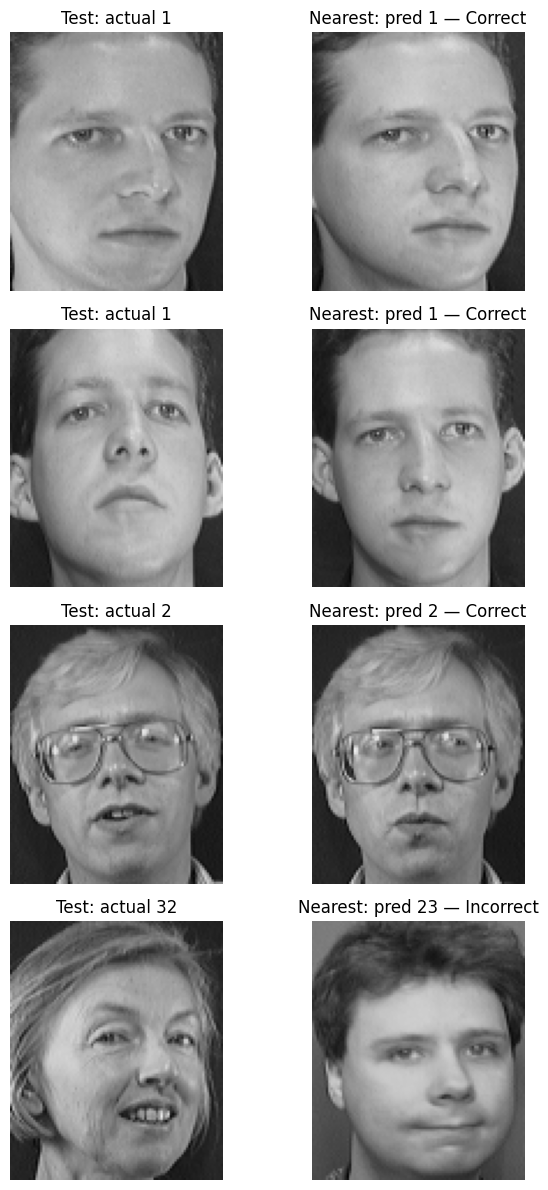

In [30]:
correct_indices = np.flatnonzero(pred_weighted == y_test)
wrong_indices = np.flatnonzero(pred_weighted != y_test)
selected = np.r_[correct_indices[:3], wrong_indices]
print('Wrong raw:', np.flatnonzero(pred_raw != y_test))
print('Wrong PCA:', np.flatnonzero(pred_pca != y_test))
print('Wrong weighted:', wrong_indices)
if selected.size:
    fig, axes = plt.subplots(len(selected), 2, figsize=(7, 3*len(selected)), squeeze=False)
    for row, ti in enumerate(selected):
        nearest = idx_weighted[ti]
        axes[row,0].imshow(X_test[ti].reshape(IMAGE_SHAPE), cmap='gray', vmin=0,vmax=255)
        axes[row,1].imshow(X_train[nearest].reshape(IMAGE_SHAPE), cmap='gray',vmin=0,vmax=255)
        axes[row,0].set_title(f'Test: actual {y_test[ti]}')
        axes[row,1].set_title(f'Nearest: pred {pred_weighted[ti]} — {"Correct" if pred_weighted[ti]==y_test[ti] else "Incorrect"}')
        axes[row,0].axis('off'); axes[row,1].axis('off')
    plt.tight_layout(); plt.savefig(RESULTS_DIR / 'face_matching_examples.png', dpi=220); plt.show()

In [31]:
final_rows = []
final_predictions = {}
for name, cfg in final_configs.items():
    k = cfg['k']
    basis = Vt[:k].T  # fit on OUTER training only
    train_features = A @ basis
    test_features = (X_test.astype(np.float64)-mean_face) @ basis
    clf = cfg['model']; clf.fit(train_features, y_train)
    pred = clf.predict(test_features)
    final_predictions[name] = pred
    final_rows.append({'Model':name, 'Features':k, 'Correct':int(np.sum(pred==y_test)),
                       'Test Accuracy (%)':100*np.mean(pred==y_test)})
final_results_df = pd.DataFrame(final_rows)
display(final_results_df)
final_results_df.to_csv(RESULTS_DIR / 'part_d_classifier_comparison.csv', index=False)

,Model,Features,Correct,Test Accuracy (%)
0,KNN (K=1),40,79,98.75
1,Linear SVM,100,79,98.75
2,RBF SVM,40,79,98.75
3,Logistic Regression,84,78,97.50


,Model,Features,Correct,Test Accuracy (%)
0,Raw Pixels + Euclidean,10304,79,98.75
1,PCA + Euclidean,99,79,98.75
2,PCA + Weighted Euclidean (alpha=0.25),99,79,98.75
3,KNN (K=1),40,79,98.75
4,Linear SVM,100,79,98.75
5,RBF SVM,40,79,98.75
6,Logistic Regression,84,78,97.50


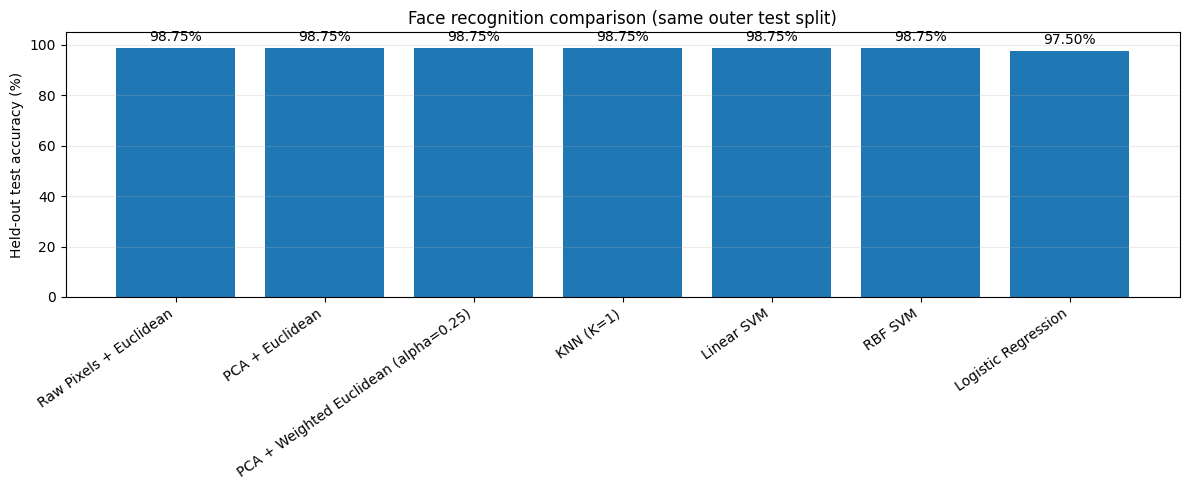

In [32]:
all_results = pd.concat([part_c_summary, final_results_df], ignore_index=True)
display(all_results)
all_results.to_csv(RESULTS_DIR / 'final_model_comparison.csv', index=False)
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(all_results['Model'], all_results['Test Accuracy (%)'])
ax.bar_label(bars, fmt='%.2f%%', padding=3)
ax.set_ylim(0, 105); ax.set_ylabel('Held-out test accuracy (%)')
ax.set_title('Face recognition comparison (same outer test split)')
ax.tick_params(axis='x', labelrotation=35)
for lbl in ax.get_xticklabels(): lbl.set_ha('right')
ax.grid(axis='y', alpha=.25)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'final_model_comparison.png', dpi=220); plt.show()